Install LIME

In [1]:
pip install lime

Note: you may need to restart the kernel to use updated packages.Requirement already satisfied: lime in c:\users\vineetha n\appdata\roaming\python\python312\site-packages (0.2.0.1)



Import packages

In [2]:
# Import necessary libraries

import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import make_pipeline
from lime.lime_text import LimeTextExplainer
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
from collections import OrderedDict

Load training data

In [3]:
# Load training data
train_df = pd.read_csv("train.csv")
print("Train shape : ", train_df.shape)
print(train_df.head)

Train shape :  (1306122, 3)
<bound method NDFrame.head of                           qid  \
0        00002165364db923c7e6   
1        000032939017120e6e44   
2        0000412ca6e4628ce2cf   
3        000042bf85aa498cd78e   
4        0000455dfa3e01eae3af   
...                       ...   
1306117  ffffcc4e2331aaf1e41e   
1306118  ffffd431801e5a2f4861   
1306119  ffffd48fb36b63db010c   
1306120  ffffec519fa37cf60c78   
1306121  ffffed09fedb5088744a   

                                             question_text  target  
0        How did Quebec nationalists see their province...       0  
1        Do you have an adopted dog, how would you enco...       0  
2        Why does velocity affect time? Does velocity a...       0  
3        How did Otto von Guericke used the Magdeburg h...       0  
4        Can I convert montra helicon D to a mountain b...       0  
...                                                    ...     ...  
1306117  What other technical skills do you need as a c...    

Display rows with NaN values

In [4]:
# Display rows with NaN values
nan_rows = train_df[train_df.isna().any(axis=1)]
print(nan_rows)

Empty DataFrame
Columns: [qid, question_text, target]
Index: []


Print train

In [5]:
# Remove rows with NaN values
train_df = train_df.dropna()
print("Train shape : ", train_df.shape)
print(train_df.head)

Train shape :  (1306122, 3)
<bound method NDFrame.head of                           qid  \
0        00002165364db923c7e6   
1        000032939017120e6e44   
2        0000412ca6e4628ce2cf   
3        000042bf85aa498cd78e   
4        0000455dfa3e01eae3af   
...                       ...   
1306117  ffffcc4e2331aaf1e41e   
1306118  ffffd431801e5a2f4861   
1306119  ffffd48fb36b63db010c   
1306120  ffffec519fa37cf60c78   
1306121  ffffed09fedb5088744a   

                                             question_text  target  
0        How did Quebec nationalists see their province...       0  
1        Do you have an adopted dog, how would you enco...       0  
2        Why does velocity affect time? Does velocity a...       0  
3        How did Otto von Guericke used the Magdeburg h...       0  
4        Can I convert montra helicon D to a mountain b...       0  
...                                                    ...     ...  
1306117  What other technical skills do you need as a c...    

Train and val data

In [6]:
# Split the data into training and validation sets
train_df, val_df = train_test_split(train_df, test_size=0.1, random_state=2018)

In [7]:
print(val_df)

                          qid  \
1092525  d61b098340966d9d6501   
1024842  c8d5c445fce3c312ca5f   
742735   9177e73a312fb5ff9e43   
163622   1ffecf3a38aa5062f51c   
1115967  daaea60735fcb5f49b12   
...                       ...   
1299477  feb0053f32eda8483c9f   
972288   be7afe3c3888bdaf322f   
902037   b0bf236fb7298811f4f6   
397790   4ded8f8f0a7d662bc43e   
515698   64f7c824cc2e2363c8c2   

                                             question_text  target  
1092525     What is the physical peak a human can achieve?       0  
1024842        What is the society like in United Kingdom?       0  
742735   How should I deal with flight instructors who ...       0  
163622   Can you take credit for subconscious acts? And...       0  
1115967  What master programs are taught in English in ...       0  
...                                                    ...     ...  
1299477               How do you define a great spectacle?       0  
972288   When will Quora stop so many utterly stupi

Select sample val data

In [8]:
# Select specific rows from validation set based on qid for inspection
df_select = pd.concat([val_df[val_df['qid'] == '0e1ef5fd2470e01ece3d'], val_df[val_df['qid'] == '1397322310ad2a880150']], axis=0)

Select question

In [9]:
# Display the 'question_text' column of selected rows
df_select.question_text

Series([], Name: question_text, dtype: object)

Print val data head

In [10]:
# Reset index of validation dataframe
val_df.reset_index(drop=True, inplace=True)
print(val_df)

                         qid  \
0       d61b098340966d9d6501   
1       c8d5c445fce3c312ca5f   
2       9177e73a312fb5ff9e43   
3       1ffecf3a38aa5062f51c   
4       daaea60735fcb5f49b12   
...                      ...   
130608  feb0053f32eda8483c9f   
130609  be7afe3c3888bdaf322f   
130610  b0bf236fb7298811f4f6   
130611  4ded8f8f0a7d662bc43e   
130612  64f7c824cc2e2363c8c2   

                                            question_text  target  
0          What is the physical peak a human can achieve?       0  
1             What is the society like in United Kingdom?       0  
2       How should I deal with flight instructors who ...       0  
3       Can you take credit for subconscious acts? And...       0  
4       What master programs are taught in English in ...       0  
...                                                   ...     ...  
130608               How do you define a great spectacle?       0  
130609  When will Quora stop so many utterly stupid qu...       1  
130

TF-IDF vectorizer

In [11]:
# Create a TF-IDF vectorizer and transform the training and validation data

## vectorize to tf-idf vectors
tfidf_vc = TfidfVectorizer(min_df = 10, max_features = 100000, analyzer = "word", ngram_range = (1, 2), stop_words = 'english', lowercase = True)
train_vc = tfidf_vc.fit_transform(train_df["question_text"])
val_vc = tfidf_vc.transform(val_df["question_text"])

Logistic regression model

In [12]:
# Train a Logistic Regression model on the training data

model = LogisticRegression(C = 0.5, solver = "sag")
model = model.fit(train_vc, train_df.target)

# Predict on the validation data
val_pred = model.predict(val_vc)

Evaluation metrics

In [13]:
# Calculate evaluation metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

accuracy = accuracy_score(val_df.target, val_pred)
precision = precision_score(val_df.target, val_pred)
recall = recall_score(val_df.target, val_pred)
f1 = f1_score(val_df.target, val_pred)

In [14]:
# Print evaluation metrics
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Accuracy: 0.9504566926722455
Precision: 0.6948633364750235
Recall: 0.3629538461538461
F1 Score: 0.4768372544263886


In [15]:
# Display confusion matrix
conf_matrix = confusion_matrix(val_df.target, val_pred)
print("Confusion Matrix:\n", conf_matrix)

Confusion Matrix:
 [[121193   1295]
 [  5176   2949]]


In [16]:
# Display classification report
# Define class names
class_names = ["sincere", "insincere"]
class_report = classification_report(val_df.target, val_pred, target_names=class_names)
print("Classification Report:\n", class_report)

Classification Report:
               precision    recall  f1-score   support

     sincere       0.96      0.99      0.97    122488
   insincere       0.69      0.36      0.48      8125

    accuracy                           0.95    130613
   macro avg       0.83      0.68      0.73    130613
weighted avg       0.94      0.95      0.94    130613



In [17]:
# Filter the rows where target is 1
target_1_rows = val_df[val_df['target'] == 1]

# Print the filtered rows and their row indices
print("Rows with target = 1:")
print(target_1_rows)

print("\nRow indices of rows with target = 1:")
print(target_1_rows.index.tolist())

Rows with target = 1:
                         qid  \
5       6ffde284b9ced1c44d8c   
13      6d65940d297c39901971   
60      409bd8b0cc10df2fefdd   
82      7b290f29058501942db6   
138     4f385cca187087aa075e   
...                      ...   
130569  51ba936f1b6bee4b1c11   
130571  5cba58b97d26249b6109   
130588  02a9d74fc126ddf8b941   
130598  3de0ef019c925c84c757   
130609  be7afe3c3888bdaf322f   

                                            question_text  target  
5       Sexual attraction doesn't start until a couple...       1  
13      Do psychopaths find help for boredom from psyc...       1  
60      Will Trump say he will nuke Turkey now that th...       1  
82      Why does the older generation think that just ...       1  
138     Why do most Italian women look and sound more ...       1  
...                                                   ...     ...  
130569   Can women stop wearing make-up even for one day?       1  
130571      Why is everyone sucking Modi's dick i

In [18]:
# Select a specific instance from the validation set for explanation
import numpy as np
prediction_index = 20
idx = int(val_df.index[prediction_index])
print(idx)
c = make_pipeline(tfidf_vc, model)
class_names = ["sincere", "insincere"]

# Create a LIME text explainer
explainer = LimeTextExplainer(class_names = class_names)

# Explain the prediction for the selected instance
exp = explainer.explain_instance(val_df["question_text"][idx], c.predict_proba, num_features = 10)

# Print the selected question text and its prediction probabilities
print(val_df["question_text"][idx])
print("Probability (Insincere) =", c.predict_proba([val_df["question_text"][idx]])[0, 1])
print("Probability (Sincere) =", c.predict_proba([val_df["question_text"][idx]])[0, 0])
print("True Class is:", class_names[int(val_df["target"][idx])])

20
What is the best way to get rid of tan?
Probability (Insincere) = 0.005801036337063928
Probability (Sincere) = 0.994198963662936
True Class is: sincere


In [19]:
# Get explanation weights as a list of tuples
exp.as_list()

[(np.str_('best'), -0.007998880749422147),
 (np.str_('way'), 0.0025884734319464205),
 (np.str_('tan'), -0.0012941704456471395),
 (np.str_('rid'), 0.0007089747427746152),
 (np.str_('of'), -8.636421807968777e-05),
 (np.str_('is'), -7.158991989788263e-05),
 (np.str_('the'), -7.028196848211101e-05),
 (np.str_('get'), 6.615362620865637e-05),
 (np.str_('to'), -4.20930476829106e-05),
 (np.str_('What'), -2.737388353698698e-05)]

In [20]:
# Print original prediction probability
print('Original prediction:',  model.predict_proba(val_vc[prediction_index])[0, 1])

# Create a copy of the selected instance's TF-IDF vector and modify specific features
tmp = val_vc[prediction_index].copy()
tmp[0, tfidf_vc.vocabulary_['best']] = 0
tmp[0, tfidf_vc.vocabulary_['rid']] = 0

# Print prediction after removing specific features
print('Prediction after removing some features:', model.predict_proba(tmp)[0, 1])

# Print the difference in prediction probabilities
print('Difference:', model.predict_proba(tmp)[0, 1] - model.predict_proba(val_vc[prediction_index])[0, 1])

Original prediction: 0.005801036337063928
Prediction after removing some features: 0.012966167833096414
Difference: 0.007165131496032486


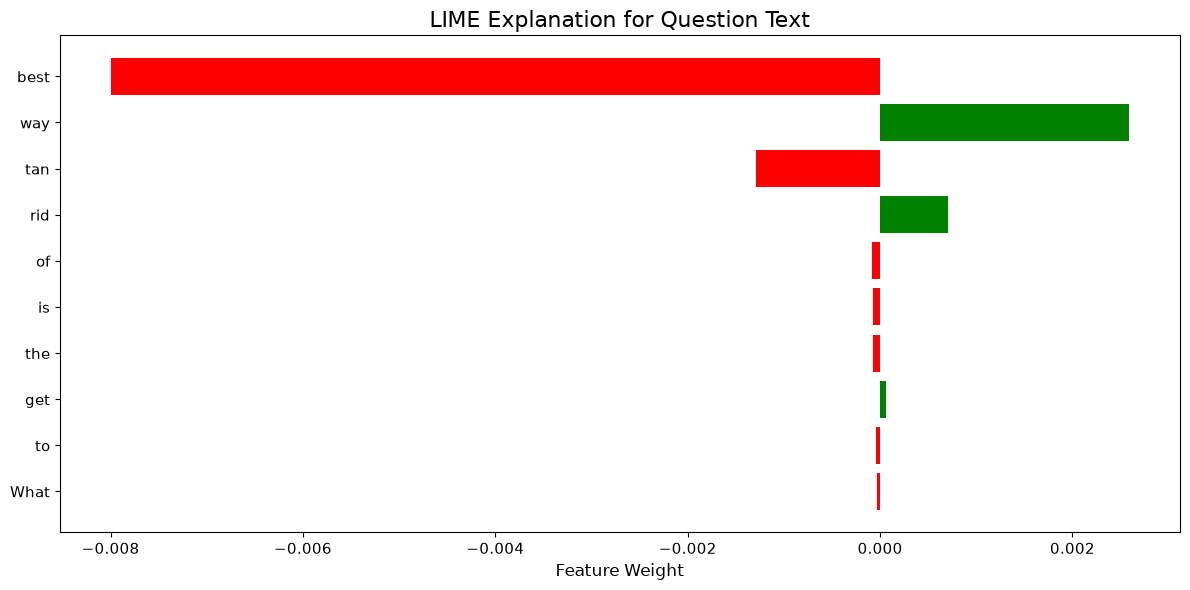

In [21]:
import matplotlib.pyplot as plt

# Generate the LIME explanation as a Matplotlib figure
fig = exp.as_pyplot_figure(label=1)

# Improve plot quality and readability
fig.set_size_inches(12, 6)
plt.title("LIME Explanation for Question Text", fontsize=16)
plt.xlabel("Feature Weight", fontsize=12)
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)

plt.tight_layout()
plt.show()